## Load

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress
from pathlib import Path
import glob

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({
    'figure.figsize': (10, 6),
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'legend.fontsize': 11,
    'lines.linewidth': 1.5,
    'font.family': 'sans-serif'
})

root = Path.cwd()
base_dir = root / "results" / "tabpfn_diagnostics_rollouts"
output_dir = root / "results" / "artifacts" / "tabpfn_diagnostics"
output_dir.mkdir(parents=True, exist_ok=True)

file_pattern = base_dir / "tabpfn_drift_diagnostics_raw_r*.csv"
all_files = sorted(glob.glob(str(file_pattern)))
print(f"Found {len(all_files)} rollout files.")

df_list = []
for i, file in enumerate(all_files):
    temp_df = pd.read_csv(file)
    temp_df['rollout_id'] = i + 1
    temp_df['abs_drift'] = temp_df['expected_drift_bn'].abs()
    df_list.append(temp_df)

df_all = pd.concat(df_list, ignore_index=True)
df_mean = df_all.groupby('step_n').mean(numeric_only=True).reset_index()

print(f"{df_all['rollout_id'].nunique()} rollouts, "
      f"n from {df_all['step_n'].min()} to {df_all['step_n'].max()}, "
      f"{df_all['step_n'].nunique()} grid points")

Found 20 rollout files.
20 rollouts, n from 125 to 1025, 125 grid points


## Partial Sums 

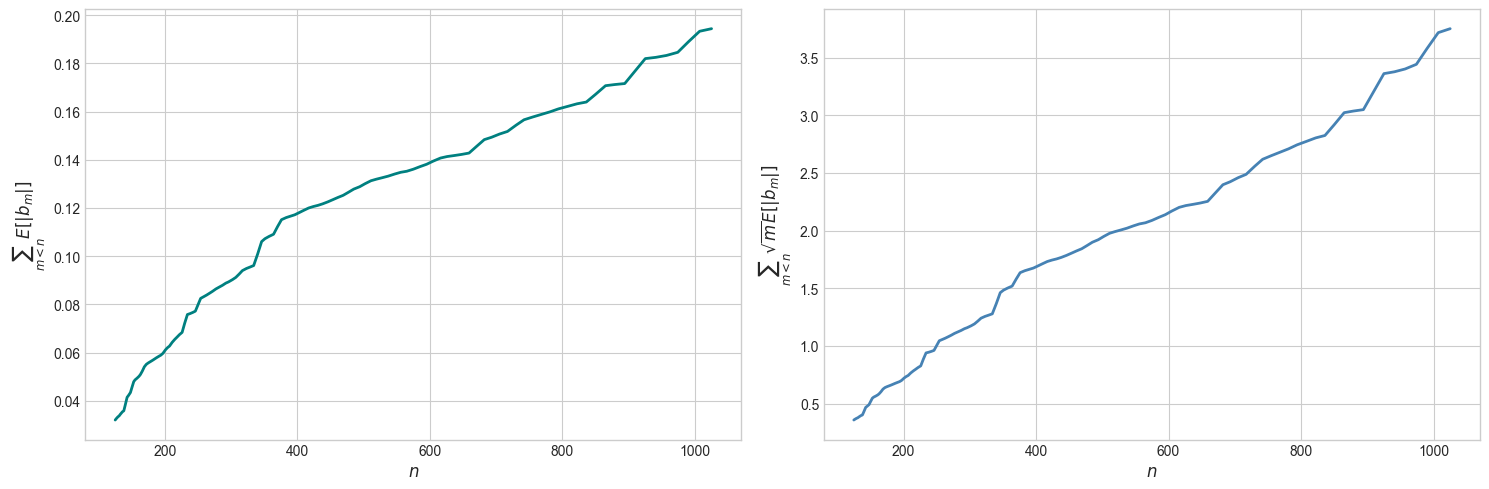

In [26]:
n_0 = 25
df_mean['n_diff'] = df_mean['step_n'].diff().fillna(df_mean['step_n'].iloc[0] - n_0)

df_mean['trap_abs_drift'] = df_mean['abs_drift'].rolling(window=2).mean().fillna(df_mean['abs_drift'])
df_mean['S_n'] = (df_mean['trap_abs_drift'] * df_mean['n_diff']).cumsum()

df_mean['weighted_drift'] = np.sqrt(df_mean['step_n']) * df_mean['abs_drift']
df_mean['trap_weighted_drift'] = df_mean['weighted_drift'].rolling(window=2).mean().fillna(df_mean['weighted_drift'])
df_mean['T_n'] = (df_mean['trap_weighted_drift'] * df_mean['n_diff']).cumsum()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

ax1.plot(df_mean['step_n'], df_mean['S_n'], color='teal', linewidth=2)
ax1.set_title("")
ax1.set_xlabel("$n$")
ax1.set_ylabel(r"$\sum_{m<n} E[|b_m|]$")

ax2.plot(df_mean['step_n'], df_mean['T_n'], color='steelblue', linewidth=2)
ax2.set_title("")
ax2.set_xlabel("$n$")
ax2.set_ylabel(r"$\sum_{m<n} \sqrt{m} E[|b_m|]$")

plt.tight_layout()
plt.savefig(output_dir / "partial_sums.pdf", bbox_inches='tight', dpi=300)
plt.show()

## Power Law First Moment

=== Drift (First Moment) ===
Slope (-β): -0.86 (95% CI: [-1.06, -0.65])
R²: 0.35



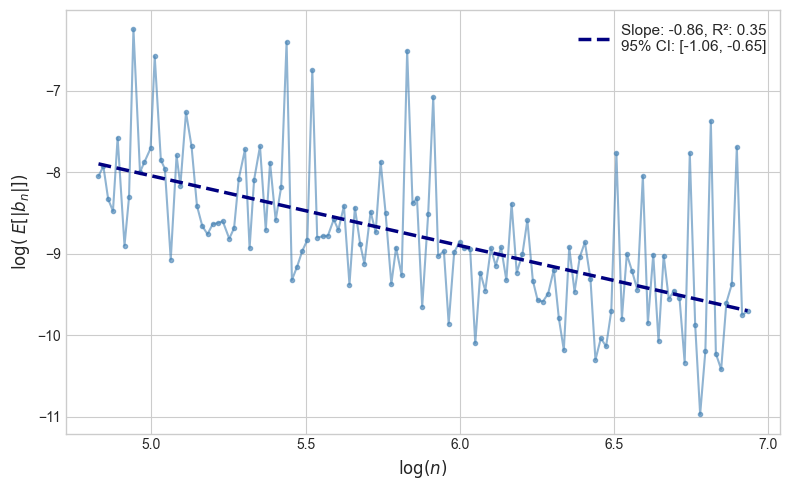

In [27]:
df_beta = df_mean[df_mean['abs_drift'] > 0].copy()

log_n = np.log(df_beta['step_n'])
log_bn = np.log(df_beta['abs_drift'])

beta_res = linregress(log_n, log_bn)
slope_ci_lower = beta_res.slope - 1.96 * beta_res.stderr
slope_ci_upper = beta_res.slope + 1.96 * beta_res.stderr

print("=== Drift (First Moment) ===")
print(f"Slope (-β): {beta_res.slope:.2f} (95% CI: [{slope_ci_lower:.2f}, {slope_ci_upper:.2f}])")
print(f"R²: {beta_res.rvalue**2:.2f}\n")

plt.figure(figsize=(8, 5))

plt.plot(log_n, log_bn, marker='.', linestyle='-', color='steelblue', alpha=0.6)

label_str = f'Slope: {beta_res.slope:.2f}, R²: {beta_res.rvalue**2:.2f}\n95% CI: [{slope_ci_lower:.2f}, {slope_ci_upper:.2f}]'
plt.plot(log_n, beta_res.intercept + beta_res.slope * log_n, 
         linestyle='--', color='navy', linewidth=2.5, label=label_str)

plt.xlabel(r'$\log(n)$')
plt.ylabel(r'$\log( \; E[|b_n|])$')
plt.title('')
plt.legend()
plt.tight_layout()
plt.savefig(output_dir / "power_law_first.pdf", bbox_inches='tight', dpi=300)
plt.show()

## Power Law Fit: Second Moment

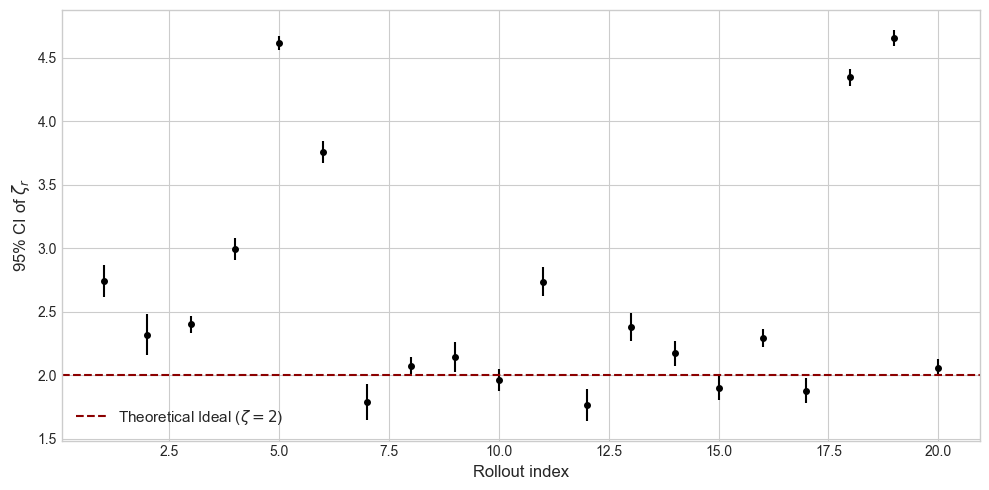

In [28]:
rollout_ids, zetas, zeta_errors = [], [], []

for r_id in sorted(df_all['rollout_id'].unique()):
    df_r = df_all[(df_all['rollout_id'] == r_id) & (df_all['expected_squared_drift_bn_prime'] > 0)]
    if len(df_r) > 1:
        log_n_r = np.log(df_r['step_n'])
        log_bn_prime = np.log(df_r['expected_squared_drift_bn_prime'])
        zeta_res = linregress(log_n_r, log_bn_prime)
        
        rollout_ids.append(r_id)
        zetas.append(-zeta_res.slope)
        zeta_errors.append(1.96 * zeta_res.stderr)

plt.figure(figsize=(10, 5))

plt.errorbar(rollout_ids, zetas, yerr=zeta_errors, fmt='o', color='black', 
             markersize=4, ecolor='black', capsize=0, elinewidth=1.5)

plt.axhline(y=2.0, color='darkred', linestyle='--', linewidth=1.5, label=r'Theoretical Ideal ($\zeta=2$)')

plt.xlabel('Rollout index')
plt.ylabel(r'95% CI of $\zeta_r$')
plt.title(r'')
plt.legend()
plt.tight_layout()
plt.savefig(output_dir / "power_law_second.pdf", bbox_inches='tight', dpi=300)
plt.show()

## Individual Trajectories

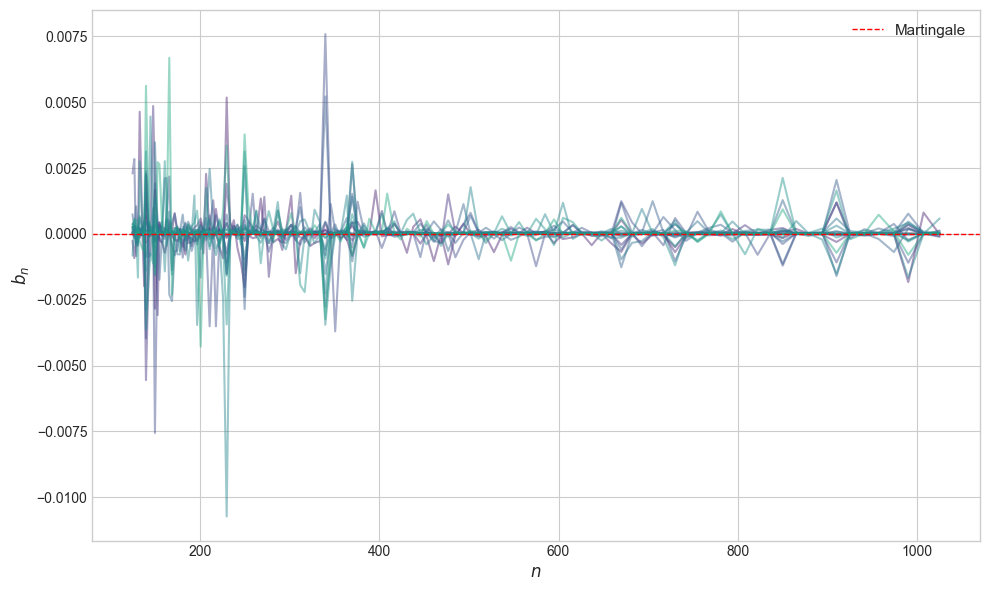

In [29]:
plt.figure(figsize=(10, 6))

# Isolate the first 20 rollouts
rollouts = df_all['rollout_id'].unique()[:20]

# Generate a cohesive palette bridging teal and navy
# We sample from 0.4 to 0.9 to avoid the colors being too light to read
colors = plt.cm.viridis(np.linspace(0.05, 0.6, len(rollouts)))


for i, r_id in enumerate(rollouts):
    df_r = df_all[df_all['rollout_id'] == r_id]
    
    # Apply the varied colors and a slightly higher alpha
    plt.plot(df_r['step_n'], df_r['expected_drift_bn'], color=colors[i], alpha=0.45, linewidth=1.5)

plt.axhline(0, color='red', linestyle='--', linewidth=1, label='Martingale')

plt.xlabel('$n$')
plt.ylabel('$b_n$')
plt.title('')
plt.legend()
plt.tight_layout()
plt.savefig(output_dir / "individual_trajectories.pdf", bbox_inches='tight', dpi=300)
plt.show()

## Mean vs SD

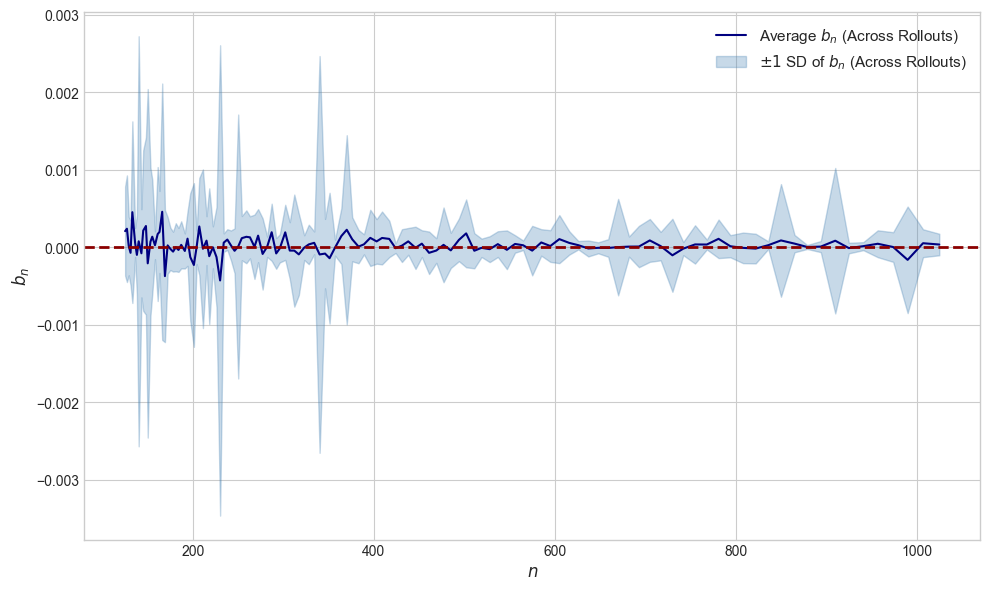

In [30]:
df_spread = df_all.groupby('step_n')['expected_drift_bn'].agg(['mean', 'std']).reset_index()

plt.figure(figsize=(10, 6))

plt.plot(df_spread['step_n'], df_spread['mean'], color='navy', label='Average $b_n$ (Across Rollouts)')

plt.fill_between(
    df_spread['step_n'], 
    df_spread['mean'] - df_spread['std'], 
    df_spread['mean'] + df_spread['std'], 
    color='steelblue', alpha=0.3, label=r'$\pm 1$ SD of $b_n$ (Across Rollouts)'
)

plt.axhline(0, color='darkred', linestyle='--', linewidth=2)

plt.xlabel('$n$')
plt.ylabel('$b_n$')
plt.title('')
plt.legend()
plt.tight_layout()
plt.savefig(output_dir / "average_vs_sd.pdf", bbox_inches='tight', dpi=300)
plt.show()

## Covariate Specific: Individual Trajectories

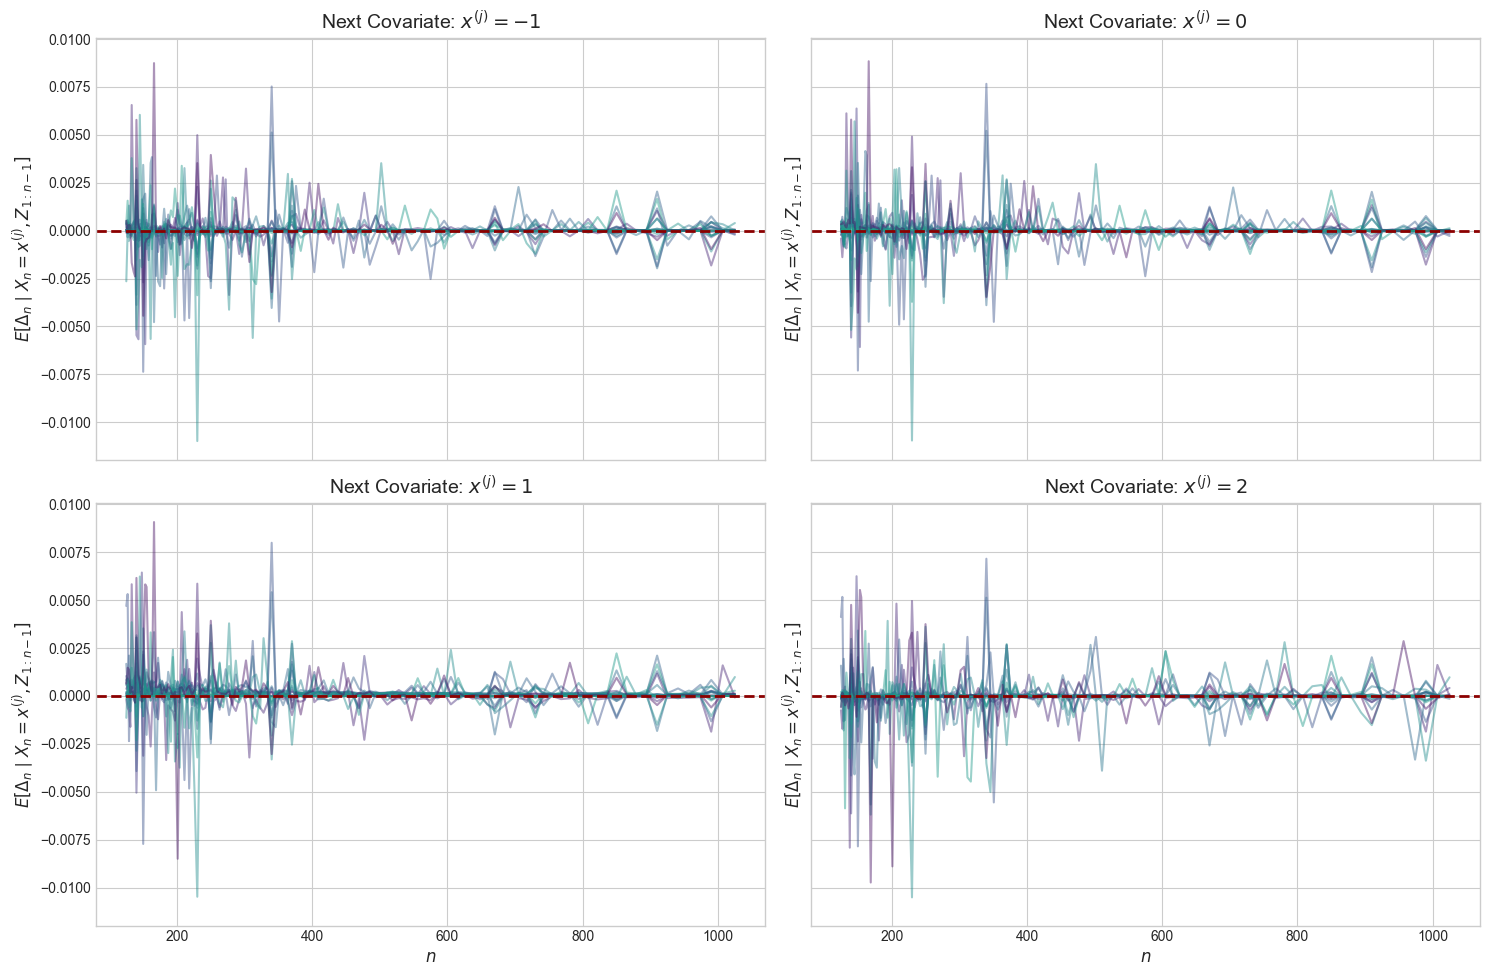

In [31]:
covariates = [
    ('-1', 'drift_given_x_minus1'),
    ('0', 'drift_given_x_0'),
    ('1', 'drift_given_x_1'),
    ('2', 'drift_given_x_2')
]

fig, axes = plt.subplots(2, 2, figsize=(15, 10), sharex=True, sharey=True)
fig.suptitle('', fontsize=16)

for ax, (x_val, col_name) in zip(axes.flatten(), covariates):
    colors = plt.cm.viridis(np.linspace(0.05, 0.6, len(rollouts)))

    for rollout_id, group_df in df_all.groupby('rollout_id'):
        ax.plot(group_df['step_n'], group_df[col_name], color=colors[rollout_id % len(colors)], alpha=0.45, linewidth=1.5)
    
    ax.axhline(0, color='darkred', linestyle='--', linewidth=2)
    ax.set_title(rf'Next Covariate: $x^{{(j)}} = {x_val}$')
    ax.set_ylabel(rf'$E[\Delta_n \mid X_n = x^{{(j)}}, Z_{{1:n-1}}]$')

for ax in axes[1, :]:
    ax.set_xlabel('$n$')

plt.tight_layout()
plt.savefig(output_dir / "covariate_individual_trajectories.pdf", bbox_inches='tight', dpi=300)
plt.show()

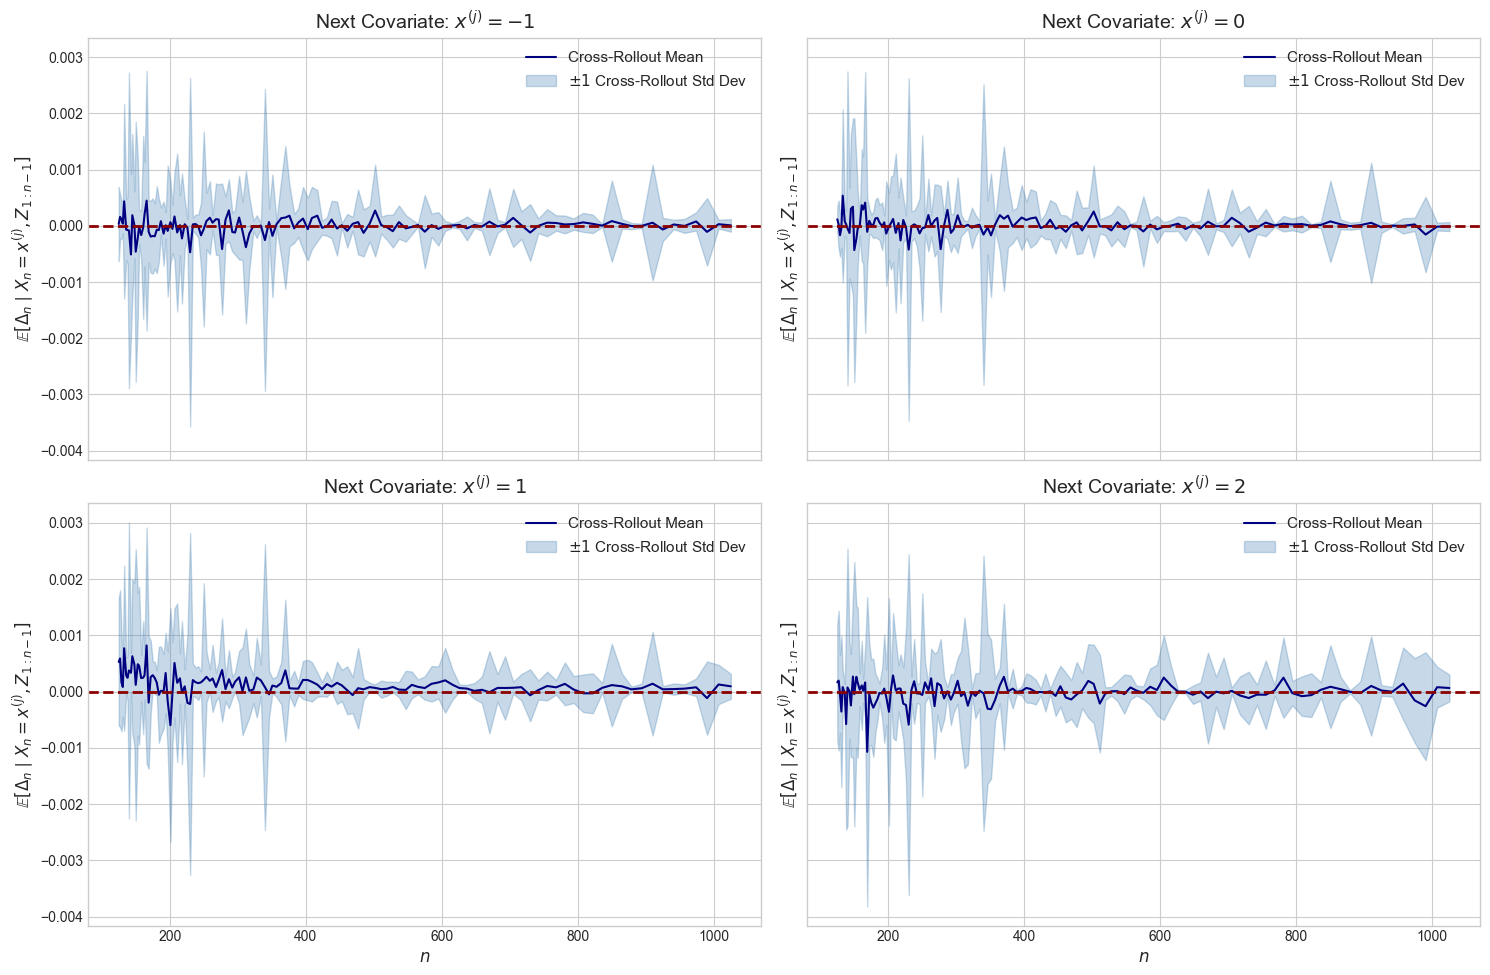

In [32]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10), sharex=True, sharey=True)
fig.suptitle(r'', fontsize=16)

for ax, (x_val, col_name) in zip(axes.flatten(), covariates):
    # Calculate the mean and std of the signed conditional drift at each step n
    df_spread_cov = df_all.groupby('step_n')[col_name].agg(['mean', 'std']).reset_index()
    
    # Plot the cross-rollout mean (The Signal)
    ax.plot(df_spread_cov['step_n'], df_spread_cov['mean'], color='navy', label='Cross-Rollout Mean')
    
    # Fill the area representing +/- 1 Standard Deviation (The Noise)
    ax.fill_between(
        df_spread_cov['step_n'], 
        df_spread_cov['mean'] - df_spread_cov['std'], 
        df_spread_cov['mean'] + df_spread_cov['std'], 
        color='steelblue', alpha=0.3, label=r'$\pm 1$ Cross-Rollout Std Dev'
    )
    
    ax.axhline(0, color='darkred', linestyle='--', linewidth=2)
    
    ax.set_title(rf'Next Covariate: $x^{{(j)}} = {x_val}$')
    # Y-label uses the exact conditional expectation notation
    ax.set_ylabel(rf'$\mathbb{{E}}[\Delta_n \mid X_n = x^{{(j)}}, Z_{{1:n-1}}]$')
    ax.legend()

for ax in axes[1, :]:
    ax.set_xlabel('$n$')

plt.tight_layout()
plt.savefig(output_dir / "covariate_mean_sd.pdf", bbox_inches='tight', dpi=300)
plt.show()

## Signed Conditions

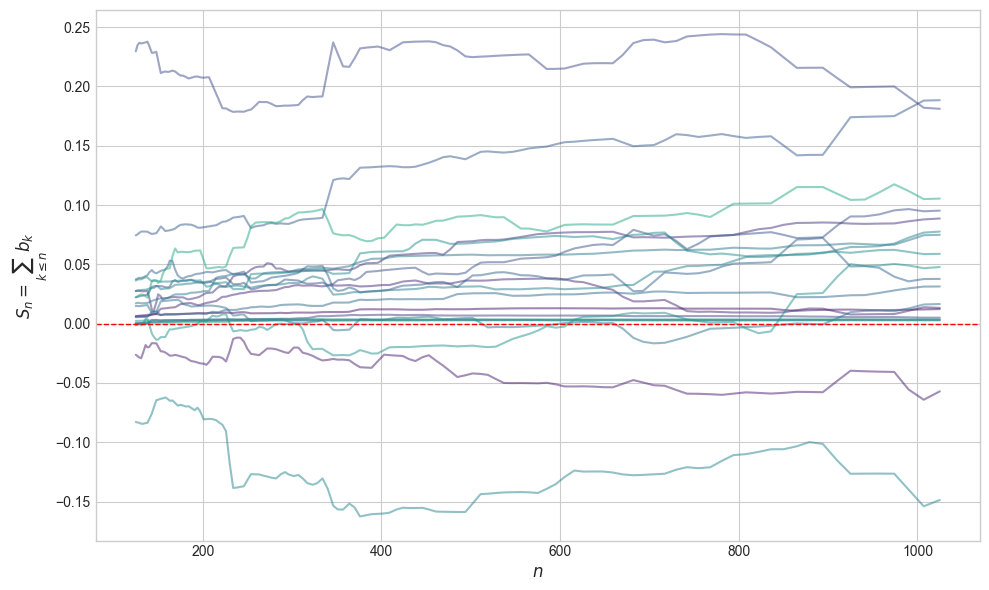

In [33]:
n_0 = 25

plt.figure(figsize=(10, 6))

rollouts = np.sort(df_all['rollout_id'].unique())
colors = plt.cm.viridis(np.linspace(0.05, 0.6, len(rollouts)))

for i, r_id in enumerate(rollouts):
    df_r = df_all[df_all['rollout_id'] == r_id].sort_values('step_n').copy()

    # 1. width of the block each grid point stands for
    df_r['n_diff'] = df_r['step_n'].diff().fillna(df_r['step_n'].iloc[0] - n_0)

    # 2. trapezoidal average of the signed drift across each block
    df_r['trap_drift'] = (df_r['expected_drift_bn']
                          .rolling(window=2).mean()
                          .fillna(df_r['expected_drift_bn']))

    # 3. S_n = sum_{k <= n} b_k
    df_r['S_n'] = (df_r['trap_drift'] * df_r['n_diff']).cumsum()

    plt.plot(df_r['step_n'], df_r['S_n'],
             color=colors[i], alpha=0.5, linewidth=1.5)

plt.axhline(0, color='red', linestyle='--', linewidth=1)

plt.xlabel('$n$')
plt.ylabel(r'$S_n = \sum_{k \leq n} b_k$')
plt.title('')
plt.tight_layout()
plt.savefig(output_dir / "partial_sums_signed.pdf", bbox_inches='tight', dpi=300)
plt.show()

# Partial Sum S_n converging to something (not necessarily 0) could hint at signed tail sums converging to zero
# met for some trajectories here below, but overall not really stable up to current N 
# weighted by trapezoidal